<>:375: SyntaxWarning: invalid escape sequence '\m'
<>:376: SyntaxWarning: invalid escape sequence '\m'
<>:391: SyntaxWarning: invalid escape sequence '\e'
<>:391: SyntaxWarning: invalid escape sequence '\s'
<>:391: SyntaxWarning: invalid escape sequence '\s'
<>:403: SyntaxWarning: invalid escape sequence '\m'
<>:404: SyntaxWarning: invalid escape sequence '\m'
<>:419: SyntaxWarning: invalid escape sequence '\e'
<>:419: SyntaxWarning: invalid escape sequence '\s'
<>:419: SyntaxWarning: invalid escape sequence '\s'
<>:442: SyntaxWarning: invalid escape sequence '\m'
<>:443: SyntaxWarning: invalid escape sequence '\m'
<>:375: SyntaxWarning: invalid escape sequence '\m'
<>:376: SyntaxWarning: invalid escape sequence '\m'
<>:391: SyntaxWarning: invalid escape sequence '\e'
<>:391: SyntaxWarning: invalid escape sequence '\s'
<>:391: SyntaxWarning: invalid escape sequence '\s'
<>:403: SyntaxWarning: invalid escape sequence '\m'
<>:404: SyntaxWarning: invalid escape sequence '\m'
<>:419: Synt

Loading datasets
Plotting training data


/tmp/ipykernel_688/2832317323.py:318: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()


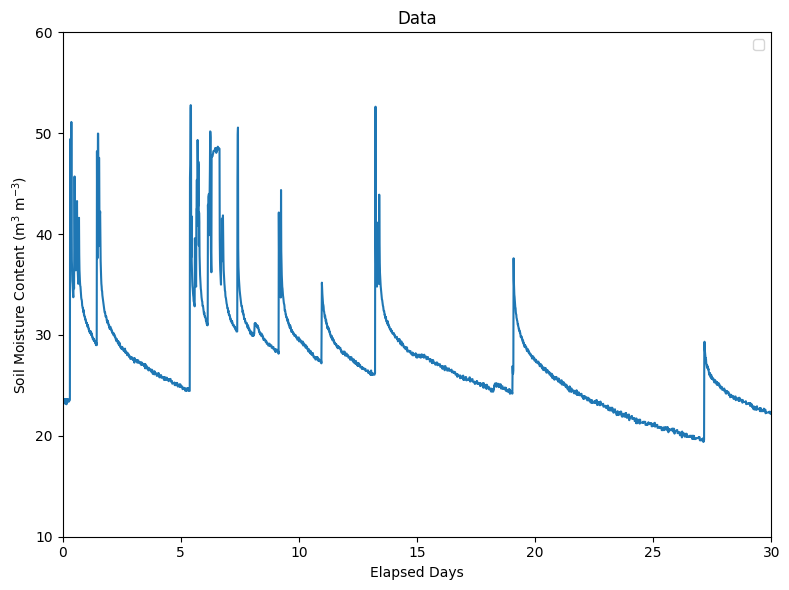

Using a multiplication of the rbf and periodic kernel
Initial GP Parameters: {'kernel': {'lengthscale': 5.0, 'variance': 1.0, 'period': 5.0}, 'likelihood': {'variance': 1.0}, 'mean': {'constant': 30.0}}
Optimised GP Parameters: {'RBF': {'lengthscale': Array(0.80480538, dtype=float64), 'variance': Array(16.68766406, dtype=float64)}, 'Periodic': {'lengthscale': Array(1.03327739, dtype=float64), 'variance': Array(1.52754346, dtype=float64), 'period': Array(1.06875076, dtype=float64)}, 'likelihood': {'variance': 0.28712300538693253}}
Plotting GP


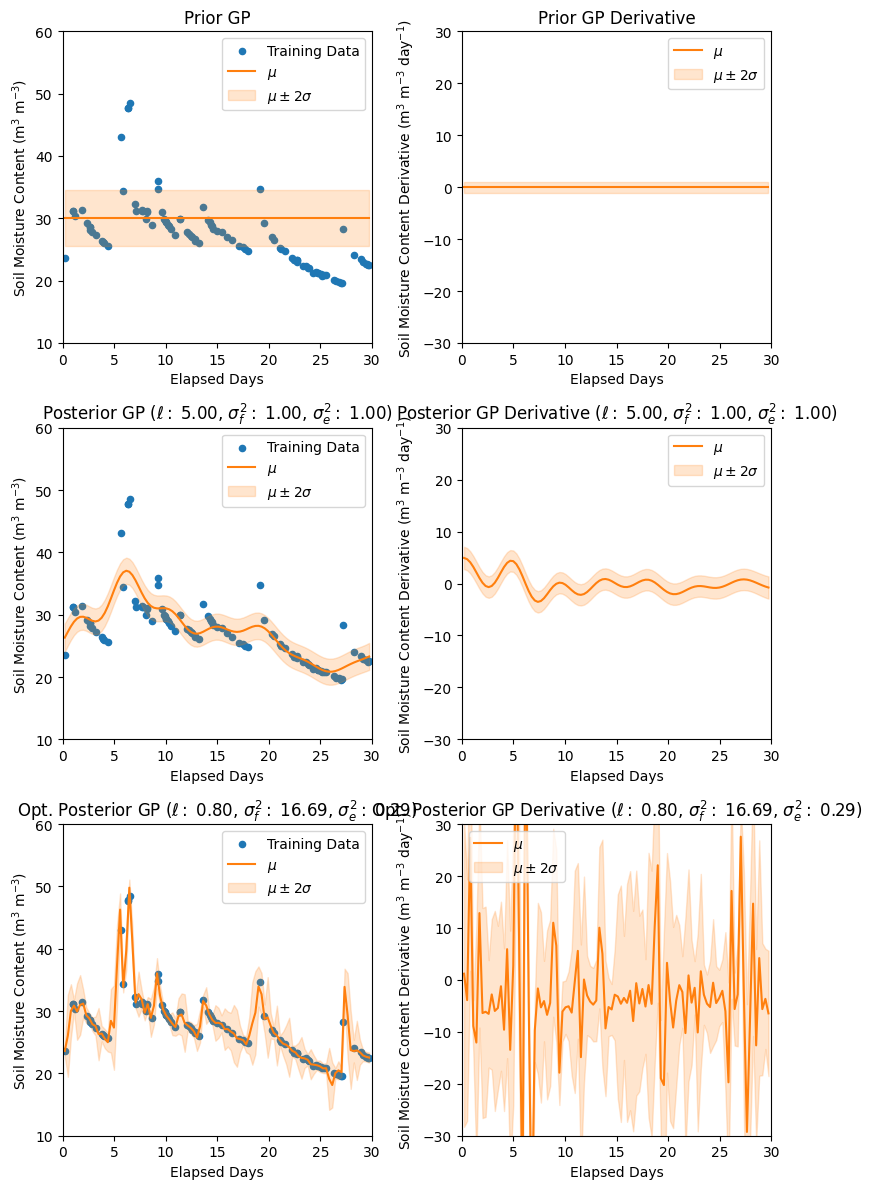

Rejection Sampling
 1/10 Accepted Samples: 195
 2/10 Accepted Samples: 152
 3/10 Accepted Samples: 124
 4/10 Accepted Samples: 126
 5/10 Accepted Samples: 129
 6/10 Accepted Samples: 132
 7/10 Accepted Samples: 135
 8/10 Accepted Samples: 113
 9/10 Accepted Samples: 124
10/10 Accepted Samples: 102
Calculating Field Capacity
Number of Samples: 1332
Estimated Field Capacity: 26.857853152115144
100-Sample Variance of Field Capacity: 0.13464632290973358


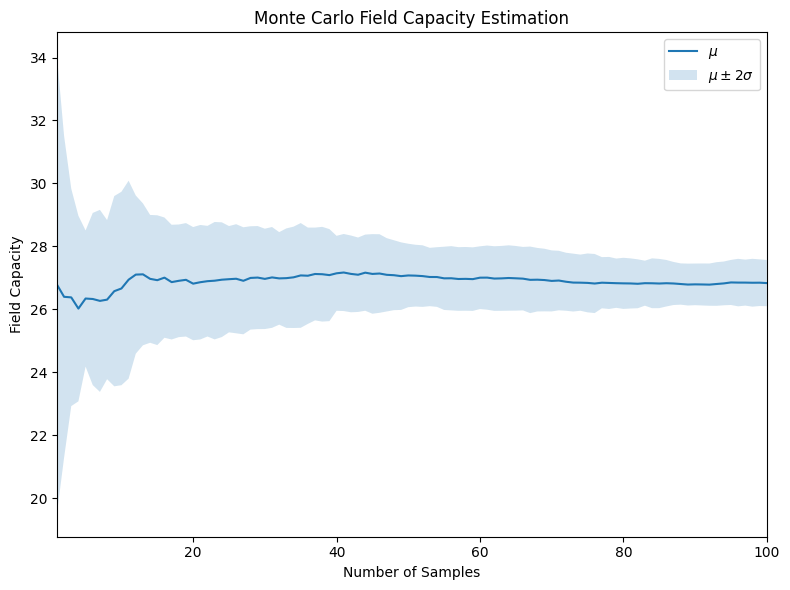

Finished Script


In [2]:
import jax
import jax.numpy as jnp
import jax.random as jr
from jax import config
from jaxtyping import (
    PyTree,
    Array,
    Float,
    Int,
    install_import_hook,
)

config.update("jax_enable_x64", True)

with install_import_hook("gpjax", "beartype.beartype"):
    import gpjax as gpx
from gpjax.kernels.computations import DenseKernelComputation

from tqdm import tqdm
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


########
# Data #
########

def get_datasets(total_iter, dataset_size, rnd_key):
    df_raw = pd.read_csv('../data/RainGarden.csv')
    df_f = df_raw.iloc[7000:9880]

    # convert to unix time (and reset by start time) and add zero dimension
    xs = df_f['Time']
    xs = (pd.to_datetime(xs, format='%m/%d/%y %H:%M').astype(int) // 1e9).values
    xs = xs / (60 * 60 * 24)
    xs = xs - xs[0]
    xs = xs.astype(float)
    xs = xs[:, None]
    xs = add_zeros_dim(xs)

    ys = df_f[f'wfv_1'].values[:, None]

    full_data = gpx.Dataset(xs, ys)

    datasets = []
    for i in range(total_iter):
        # select random data for each dataset
        rnd_key, subkey = jr.split(rnd_key)
        idx = np.array(jr.choice(subkey, np.arange(xs.shape[0]), shape=(dataset_size,), replace=True))
        xs = jnp.array(xs[idx])
        ys = jnp.array(ys[idx])
        datasets.append(gpx.Dataset(xs, ys))

    return full_data, datasets, rnd_key

def add_zeros_dim(xs):
    zeros = np.zeros((xs.shape[0], 1))
    return np.concatenate([xs, zeros], axis=1)

def add_ones_dim(xs):
    ones = np.ones((xs.shape[0], 1))
    return np.concatenate([xs, ones], axis=1)

#######
# Vis #
#######

def format_data_to_plot(D):
    x = D.X[:, 0]
    y = D.y

    # need to sort the data for plotting
    argsort = np.argsort(x)
    x = x[argsort]
    y = y[argsort]

    return x, y

def format_standard_plot(ax):
    ax.set_xlabel("Elapsed Days")
    ax.set_ylabel("Soil Moisture Content (m$^3$ m$^{-3}$)")
    ax.set_xlim([0, 30])
    ax.set_ylim([10, 60])

def format_derivative_plot(ax):
    ax.set_xlabel("Elapsed Days")
    ax.set_ylabel("Soil Moisture Content Derivative (m$^3$ m$^{-3}$ day$^{-1}$)")
    ax.set_xlim([0, 30])
    ax.set_ylim([-30, 30])


######
# GP #
######

class StationaryDerivativeKernel(gpx.kernels.AbstractKernel):
    def __init__(
        self,
        kernel: gpx.kernels.AbstractKernel,
        ): 
        self.kernel = kernel
        
        super().__init__(compute_engine=DenseKernelComputation())

    def __call__(
        self, X: Float[Array, "1 D"], Xp: Float[Array, "1 D"]) -> Float[Array, "1"]:
        z = jnp.array(X[1], dtype=int)
        zp = jnp.array(Xp[1], dtype=int)

        k0 = (1 - z)* (1 - zp) * self.kernel(X, Xp)
        k1 = (z * zp) * jnp.array(jax.hessian(self.kernel, argnums=[0,1])(X, Xp), dtype=jnp.float64)[1][0][0][0]
        k2 = (z - zp) * (z - zp) * jnp.array(jax.grad(self.kernel, argnums=[0,1])(X, Xp), dtype=jnp.float64)[zp][0]

        return k0 + k1 + k2

def get_gp(kernel, init_gp_params):
    kernel = StationaryDerivativeKernel(kernel=kernel)
    mean = gpx.mean_functions.Zero()
    prior = gpx.gps.Prior(mean_function=mean, kernel=kernel)

    likelihood = gpx.likelihoods.Gaussian(num_datapoints=1, obs_stddev=np.sqrt(init_gp_params["likelihood"]["variance"]))
    posterior = prior * likelihood

    return prior, posterior
                
def fit_gp(D, posterior, init_gp_params):
    x = D.X
    y = D.y - init_gp_params["mean"]["constant"]
    train_D = gpx.Dataset(x, y)

    opt_posterior, history = gpx.fit_scipy(
    model=posterior,
    # we use the negative mll as we are minimising
    objective=lambda p, d: -gpx.objectives.conjugate_mll(p, d),
    train_data=train_D,
    verbose=False
    )
    # print(history)

    return opt_posterior

def get_gp_pred_dist(D_train, x_test, prior, posterior, opt_posterior, init_gp_mean):
    pred_dist_dict = {
        "Prior": {
            "mean": np.nan,
            "std": np.nan
        },
        "Posterior": {
            "mean": np.nan,
            "std": np.nan
        },
        "Opt. Posterior": {
            "mean": np.nan,
            "std": np.nan
        } 
    }

    x = D_train.X
    y = D_train.y - init_gp_mean
    D_train = gpx.Dataset(x, y)

    prior_dist = prior.predict(x_test)
    pred_dist_dict["Prior"]["mean"] = prior_dist.mean() + init_gp_mean
    pred_dist_dict["Prior"]["std"] = prior_dist.stddev()

    post_dist = posterior.predict(x_test, train_data=D_train)
    post_pred_dist = posterior.likelihood(post_dist)
    pred_dist_dict["Posterior"]["mean"] = post_pred_dist.mean() + init_gp_mean
    pred_dist_dict["Posterior"]["std"] = post_pred_dist.stddev()
    
    opt_post_dist = opt_posterior.predict(x_test, train_data=D_train)
    opt_post_pred_dist = opt_posterior.likelihood(opt_post_dist)
    pred_dist_dict["Opt. Posterior"]["mean"] = opt_post_pred_dist.mean() + init_gp_mean
    pred_dist_dict["Opt. Posterior"]["std"] = opt_post_pred_dist.stddev()

    return pred_dist_dict


def get_opt_parameters(posterior, init_gp_params): 
    params = init_gp_params["kernel"]

    def get_kernels(prior): 
        if 'kernel' in dir(prior):
            return getattr(prior, 'kernel'), True
        else: 
            if 'kernels' in dir(prior): 
                return getattr(prior, 'kernels'), False
            else:
                return getattr(prior, 'kernel'), False


    flag = True 
    kernels = posterior.prior 
    while flag: 
        kernels, flag = get_kernels(kernels)
        if isinstance(kernels, gpx.kernels.RBF):
            kernels = [kernels]
            break
    

    opt_params = {

    } 

    for kernel in kernels:
        name = kernel.name
        opt_params[name]={} 
        for param in params:
            attr = getattr(kernel, param, None)
            if attr is None: 
                continue 
            opt_params[name][param] = attr.value  
    opt_params['likelihood'] = {
        "variance": float(posterior.likelihood.obs_stddev)
    } 
    return opt_params


############
# Sampling #
############

def ready_sample(sample):
    sample = jnp.repeat(sample, 2)[:, None]
    second_row = jnp.tile(jnp.array([0,1]), len(sample) // 2)[:, None]
    sample = jnp.concatenate([sample, second_row], axis=1)
    return sample
    
def rejection_sampling(datasets, gp, init_gp_mean, a, b, T, total_tries, samples_per_try, var_n, rnd_key):
    samples = []

    for i in range(total_tries):
        curr_samples = []
        while len(curr_samples) < var_n:
            D_train = gpx.Dataset(datasets[i].X, datasets[i].y - init_gp_mean)

            rnd_key, subkey = jr.split(rnd_key)
            t = jr.uniform(subkey, (samples_per_try,), minval=0, maxval=T)
            t = ready_sample(t)

            rnd_key, subkey = jr.split(rnd_key)
            u = jr.uniform(subkey, (samples_per_try,), minval=0, maxval=1)

            joint_dist = gp.predict(t, train_data=D_train)
            joint_pred_dist = gp.likelihood(joint_dist)
            joint_pred_mean = joint_pred_dist.mean()
            joint_pred_std = joint_pred_dist.stddev()

            f_pred_mean = joint_pred_mean[::2] + init_gp_mean
            fd_pred_mean = joint_pred_mean[1::2]
            fd_pred_std = joint_pred_std[1::2]

            y = jax.scipy.stats.norm.cdf(b, loc=fd_pred_mean, scale=fd_pred_std) - \
                jax.scipy.stats.norm.cdf(a, loc=fd_pred_mean, scale=fd_pred_std)
            
            indices = np.where(u < y)[0]
            curr_samples.extend(f_pred_mean[indices].tolist())

            if len(curr_samples) >= var_n:
                break
        samples.append(curr_samples)
        print(f"{i+1:2}/{total_tries} Accepted Samples: {len(curr_samples)}")
        
    return samples, rnd_key


def sample_mean_variance(samples, var_n):
    means = np.zeros(var_n)
    vars = np.zeros(var_n)
    for i in range(var_n):
        means[i] = np.mean([np.mean(s[:i+1]) for s in samples])
        vars[i] = np.var([np.mean(s[:i+1]) for s in samples])
    return means, vars


########
# Main #
########


RBF_PERIODIC = True 
MIN15_PER_DAY = 4 * 24
A = -0.1 * MIN15_PER_DAY
B = -0.05 * MIN15_PER_DAY
T = 30
DATASET_SIZE = 100
TOTAL_ITER = 10
SAMPLES_PER_ITER = 1000
VAR_N = 100
INIT_GP_PARAMS = {
    "kernel": {
        "lengthscale": 5.0, 
        "variance": 1.0,
        "period": 5.0
    },
    "likelihood": {
        "variance": 1.0
    },
    "mean" :{
        "constant": 30.0
    }
}
rnd_key = jr.key(42)


print("Loading datasets")
full_data, datasets, rnd_key = get_datasets(TOTAL_ITER, DATASET_SIZE, rnd_key)

print("Plotting training data")
cols = mpl.rcParams["axes.prop_cycle"].by_key()["color"]
fig, ax = plt.subplots(1, 1, figsize=(8, 6))
x, y = format_data_to_plot(full_data)
plt.plot(x, y, color=cols[0])
format_standard_plot(ax)
ax.set_title(f"Data")
ax.legend()
plt.tight_layout()
plt.show()


kernel_rbf = gpx.kernels.RBF(
    active_dims=[0],
    lengthscale=INIT_GP_PARAMS["kernel"]["lengthscale"],
    variance=INIT_GP_PARAMS["kernel"]["variance"]
)  

kernel_periodic = gpx.kernels.Periodic(
    active_dims=[0],
    lengthscale=INIT_GP_PARAMS["kernel"]["lengthscale"],
    variance=INIT_GP_PARAMS["kernel"]["lengthscale"],
    period=INIT_GP_PARAMS["kernel"]["period"]
)
if RBF_PERIODIC: 
    print('Using a multiplication of the rbf and periodic kernel')
    kernel =  gpx.kernels.ProductKernel([kernel_rbf, kernel_periodic])
else: 
    kernel = kernel_rbf     
prior, posterior = get_gp(kernel, INIT_GP_PARAMS)
opt_posterior = fit_gp(datasets[0], posterior, INIT_GP_PARAMS)

opt_params = get_opt_parameters(opt_posterior, INIT_GP_PARAMS)

# opt_params = {
#     "kernel": {
#         "lengthscale": float(opt_posterior.prior.kernel.kernel.lengthscale.value.take(0)),
#         "variance": float(opt_posterior.prior.kernel.kernel.variance.value.take(0))
#     },
#     "likelihood": {
#         "variance": float(opt_posterior.likelihood.obs_stddev)
#     }
# }
print(f"Initial GP Parameters: {INIT_GP_PARAMS}")
print(f"Optimised GP Parameters: {opt_params}")


print(f"Plotting GP")
fig, axs = plt.subplots(3, 2, figsize=(8, 12))

x = datasets[0].X[:, 0]
x_test = np.linspace(x.min(), x.max(), 100)
x_test_gp = add_zeros_dim(x_test[:, None])

pred_dist_dict = get_gp_pred_dist(datasets[0], x_test_gp, 
                                    prior, posterior, opt_posterior, INIT_GP_PARAMS['mean']['constant'])    

for i, (title, pred_dist_dict) in enumerate(pred_dist_dict.items()):
    mean = pred_dist_dict["mean"]
    std = pred_dist_dict["std"]
    x_train, y_train = format_data_to_plot(datasets[0])
    format_standard_plot(axs[i, 0])

    axs[i, 0].scatter(x_train, y_train, color=cols[0], label='Training Data', s=20)
    axs[i, 0].plot(x_test, mean, label='$\mu$', color=cols[1])
    axs[i, 0].fill_between(x_test, mean - 2 * std, mean + 2 * std, alpha=0.2, color=cols[1], label='$\mu \pm 2\sigma$')
    axs[i, 0].legend()

    if i == 1:
        l = INIT_GP_PARAMS['kernel']['lengthscale']
        v = INIT_GP_PARAMS['kernel']['variance']
        e = INIT_GP_PARAMS['likelihood']['variance']
    elif i == 2:
        l = opt_params['RBF']['lengthscale']
        v = opt_params['RBF']['variance']
        e = opt_params['likelihood']['variance']
    
    if i == 0:
        axs[i, 0].set_title(f"{title} GP")
    else:
        axs[i, 0].set_title(f"{title} GP ($\ell:$ {l:.2f}, $\sigma^2_f:$ {v:.2f}, $\sigma^2_e:$ {e:.2f})")

# plotting derivatives 
x_test_gp = add_ones_dim(x_test[:, None])
pred_dist_dict = get_gp_pred_dist(datasets[0], x_test_gp, 
                                    prior, posterior, opt_posterior, 0.0)
for i, (title, pred_dist_dict) in enumerate(pred_dist_dict.items()):
    mean = pred_dist_dict["mean"]
    std = pred_dist_dict["std"]
    format_derivative_plot(axs[i, 1])


    axs[i, 1].plot(x_test, mean, label='$\mu$', color=cols[1])
    axs[i, 1].fill_between(x_test, mean - 2 * std, mean + 2 * std, alpha=0.2, color=cols[1], label='$\mu \pm 2\sigma$')
    axs[i, 1].legend()

    if i == 1:
        l = INIT_GP_PARAMS['kernel']['lengthscale']
        v = INIT_GP_PARAMS['kernel']['variance']
        e = INIT_GP_PARAMS['likelihood']['variance']
    elif i == 2:
        l = opt_params['RBF']['lengthscale']
        v = opt_params['RBF']['variance']
        e = opt_params['likelihood']['variance']
    
    if i == 0:
        axs[i, 1].set_title(f"{title} GP Derivative")
    else:
        axs[i, 1].set_title(f"{title} GP Derivative ($\ell:$ {l:.2f}, $\sigma^2_f:$ {v:.2f}, $\sigma^2_e:$ {e:.2f})")

plt.tight_layout()
plt.show()


print("Rejection Sampling")
samples, rnd_key = rejection_sampling(datasets, 
                                        opt_posterior, INIT_GP_PARAMS['mean']['constant'],
                                        A, B, T, TOTAL_ITER, SAMPLES_PER_ITER, VAR_N,
                                        rnd_key)

print("Calculating Field Capacity")
total_samples = np.concatenate(samples)
total_fc = np.mean(total_samples)
means, vars = sample_mean_variance(samples, VAR_N)

print(f"Number of Samples: {len(total_samples)}")
print(f"Estimated Field Capacity: {total_fc}")
print(f"{len(vars)}-Sample Variance of Field Capacity: {vars[-1]}")

# plotting variance and mean field capacity over number of samples
fig, ax = plt.subplots(1, 1, figsize=(8, 6))
plt.plot(1 + np.arange(VAR_N), means, label='$\mu$')
ax.fill_between(1 + np.arange(VAR_N), means - 2 * np.sqrt(vars), means + 2 * np.sqrt(vars), alpha=0.2, label='$\mu \pm 2\sigma$')
ax.set_xlabel("Number of Samples")
ax.set_ylabel("Field Capacity")
ax.set_xlim([1, VAR_N])
ax.set_title("Monte Carlo Field Capacity Estimation")
ax.legend()
plt.tight_layout()
plt.show()
print("Finished Script")



In [194]:
import numpy as np

# RBF kernel and its derivatives
def rbf_kernel(x, x_prime, variance, lengthscale):
    return variance * np.exp(-0.5 * (x - x_prime)**2 / lengthscale**2)

def rbf_kernel_derivative(x, x_prime, variance, lengthscale):
    return -variance * (x - x_prime) / lengthscale**2 * np.exp(-0.5 * (x - x_prime)**2 / lengthscale**2)

def rbf_kernel_second_derivative(x, x_prime, variance, lengthscale):
    diff = x - x_prime
    return variance * (1 / lengthscale**2 - diff**2 / lengthscale**4) * np.exp(-0.5 * diff**2 / lengthscale**2)

# Example: Compute mean and covariance for derivative posterior
X_train = np.arange(0, 10, 0.5)
Y_train = np.cos(X_train)  # Observed values
X_new = np.arange(0, 10, 0.1) 

variance = 1
lengthscale = 1


def get_covariance(X, XP, kernel, parameters):
    K = np.zeros(shape=(len(X), len(XP)))
    for i, x in enumerate(X): 
        for j, xp in enumerate(XP):
            K[i, j] = kernel(x, xp, *parameters)
    return K 

def get_posterior(K, Ktn, Kn, Kinv, Y_train):
    mu = np.dot(Ktn.T, Kinv).dot(Y_train)
    cov = Kn - np.dot(Ktn.T, Kinv).dot(Ktn)
    return mu, cov 

print('Computing Covariances')
K = get_covariance(X_train, X_train, rbf_kernel, (variance, lengthscale))
Ktn = get_covariance(X_train, X_new, rbf_kernel, (variance, lengthscale))
Kn = get_covariance(X_new, X_new, rbf_kernel, (variance, lengthscale))

Kdtn = get_covariance(X_train, X_new, rbf_kernel_derivative, (variance, lengthscale))
Kddtn = get_covariance(X_new, X_new, rbf_kernel_second_derivative, (variance, lengthscale))

print('Inverting matrix')
Kinv = np.linalg.inv(K)

mu, cov = get_posterior(K, Ktn, Kn, Kinv, Y_train) 
dmu, dcov = get_posterior(K, Kdtn, Kddtn, Kinv, Y_train)

X_exp = np.sort(dmu) 
X_exp_test = np.arange(min(dmu), max(dmu), 0.01) 
K_exp = get_covariance(X_exp, X_exp, rbf_kernel, (0.1, 1))
K_tnexp = get_covariance(X_exp, X_exp_test, rbf_kernel, (0.1, 1))
K_nexp = get_covariance(X_exp_test, X_exp_test, rbf_kernel, (0.1, 1))
K_exp_inv = np.linalg.inv(K_exp) 

mu_exp, cov_exp = get_posterior(K_exp, K_tnexp, K_nexp, K_exp_inv, mu)

Computing Covariances
Inverting matrix


In [1]:
K = get_covariance(Y_train, Y_train, rbf_kernel, (0.1, 1))
plt.imshow(K)

NameError: name 'get_covariance' is not defined

In [203]:
samps = np.random.multivariate_normal(K, K, 10)

ValueError: mean must be 1 dimensional

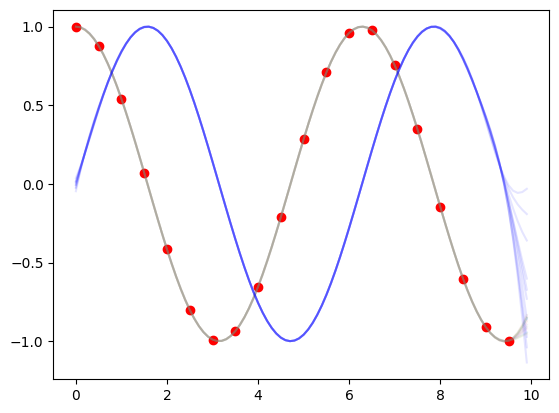

In [160]:
samps = np.random.multivariate_normal(mu, cov, 10)
_ = plt.plot(X_new, samps.T, alpha=0.1)
_ = plt.scatter(X_train, Y_train, c='red')

dsamps = np.random.multivariate_normal(dmu, dcov, 10)
_ = plt.plot(X_new, dsamps.T, alpha=0.1, c='blue')